# Theory part

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.append('../Simulations')
sys.path.append('../Calculations')
from cpp_routines import *
from data_process import *

import os
if not os.path.exists('./Plots'):
    os.mkdir('./Plots')

In [2]:
def plot_fixed_win_fail_distribution(decisions, wins, fails):
    choise = decisions[np.logical_and(decisions[:,0]==wins,decisions[:,1]==fails)][:,2:]
    leave = choise[choise[:,0]==1][:,1]
    stay = choise[choise[:,0]==0][:,1]

    plt.figure(figsize=(8,6))
    plt.hist([leave, stay], alpha=0.5, label=["leave", "stay"], range=[0.0, 100.0], bins=20)
    plt.legend(loc="upper left")
    plt.xlabel("Number of button presses")
    plt.title("Stay vs leave decisions for " + str(wins) + " wins and " + str(fails) + " fails")
    plt.show()

def plot_fixed_fail_distribution(decisions, fails):
    select_fail = decisions[decisions[:,1]==fails]
    sf_stay = select_fail[select_fail[:,2]==0][:,[0,3]]
    sf_leave = select_fail[select_fail[:,2]==1][:,[0,3]]

    plt.figure(figsize=(8,6))
    plt.xlabel("Number of wins")
    plt.ylabel("Number of remaining presses")
    plt.title("Subject decisions (" + str(fails) + " fails)")
    plt.xlim(0,15)
    plt.ylim(0,100)
    plt.scatter(sf_stay[:,0], sf_stay[:,1], c='C1', label="Stay")
    plt.scatter(sf_leave[:,0], sf_leave[:,1], c='C0', label="Leave")
    plt.legend(loc="upper right")

In [3]:
run_time = 100
number_of_runs = 10000
button_prior = (1, 1)
policy_prior = (1, 1)

# button = Button('Bernoulli', prior=(1, 1))
button = Button('Bernoulli', prior=button_prior)
policy = Policy('Bernoulli', prior=policy_prior)
# policy = Policy('Truncated', truncation=0.9)
# policy = Policy('Difference', difference=4)

unbiased_record = record_full_trials(run_time, number_of_runs, button, policy)

In [4]:
unbiased = Decision_Process(unbiased_record)

In [5]:
num_buttons, top_button_to_all = unbiased.analyze_largest_contribution()

The average number of buttons explored is 8.6215
The average reward received is 85.6487
Out of 10000 subjects in total 9760 subjects (or 97.60%) got the largest contribution from the last button
The average contribution of the button with the largest contribution is 85.83 %


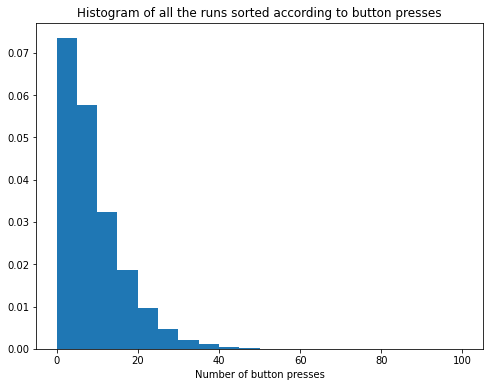

In [6]:
plt.figure(figsize=(8,6))
plt.title("Histogram of all the runs sorted according to button presses")
plt.xlabel("Number of button presses")
plt.hist(num_buttons, density=True, bins=20, range=(0, 100))
plt.savefig('Plots/button_press.png',dpi=120)
plt.show()

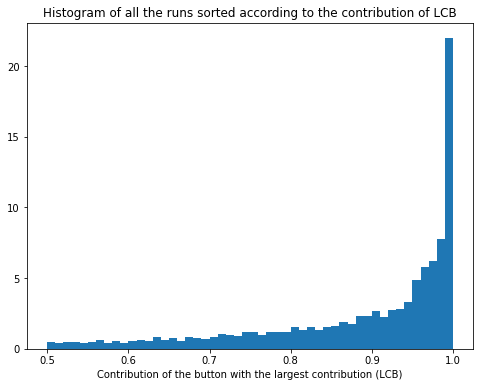

In [7]:
plt.figure(figsize=(8,6))
plt.title("Histogram of all the runs sorted according to the contribution of LCB")
plt.xlabel("Contribution of the button with the largest contribution (LCB)")
plt.hist(top_button_to_all, density=True, bins=50, range=(0.5,1));
plt.savefig('Plots/largest_contribution.png',dpi=120)
plt.show()

Total number of stay decisions is 566641
Total number of leave decisions is 18610


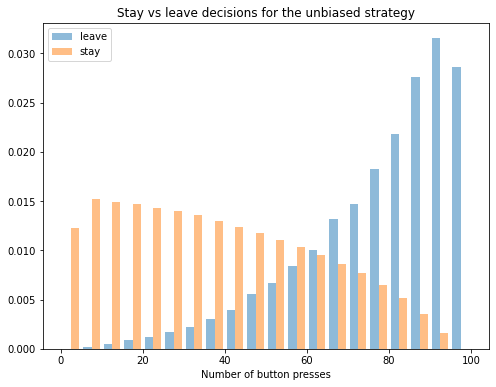

In [8]:
unbiased_data = get_wins_fails(unbiased.get_decisions(wins_more_fails=True))

plt.figure(figsize=(8,6))
plt.hist(unbiased_data, alpha=0.5, label=['leave', 'stay'], range=[0.0, 100.0], bins=20, density=True)
plt.legend(loc="upper left")
plt.title("Stay vs leave decisions for the unbiased strategy")
plt.xlabel("Number of button presses")
plt.savefig('Plots/stay_vs_leave_unbiased.png',dpi=120)
plt.show()

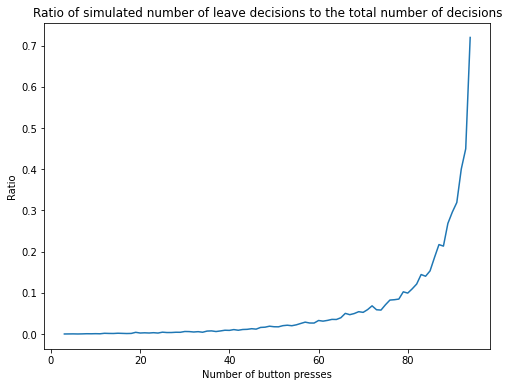

In [9]:
unbiased_aggr = aggregate_wins_fails(unbiased.get_decisions(wins_more_fails=True))

plt.figure(figsize=(8,6))
plt.title("Ratio of simulated number of leave decisions to the total number of decisions")
plt.xlabel("Number of button presses")
plt.ylabel("Ratio")
plt.plot(unbiased_aggr[:,0],unbiased_aggr[:,1]/(unbiased_aggr[:,1]+unbiased_aggr[:,2]))
plt.savefig('Plots/ratio_unbiased.png',dpi=120)
plt.show()

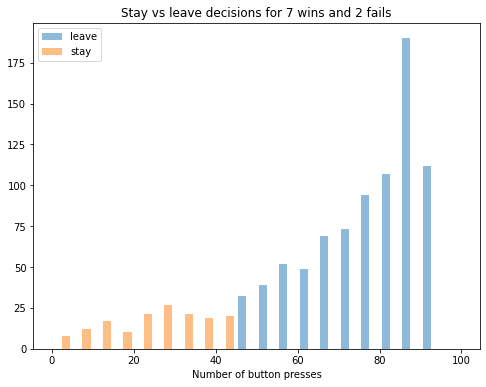

In [10]:
plot_fixed_win_fail_distribution(unbiased.get_decisions(), 7, 2)

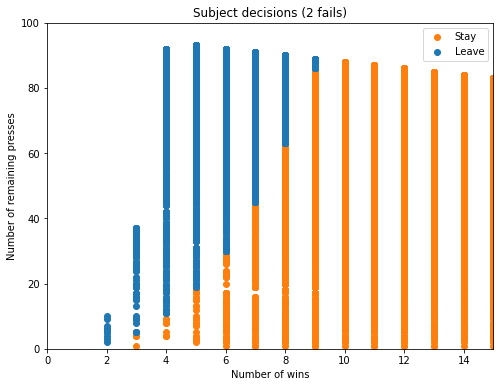

In [11]:
plot_fixed_fail_distribution(unbiased.get_decisions(), 2)

In [12]:
button = Button('Bernoulli', prior=(1, 2))
policy = Policy('Bernoulli', prior=(1, 2))
negative_bias_record = record_full_trials(100, 10000, button, policy)
negative_bias = Decision_Process(negative_bias_record)

Total number of stay decisions is 713149
Total number of leave decisions is 8174


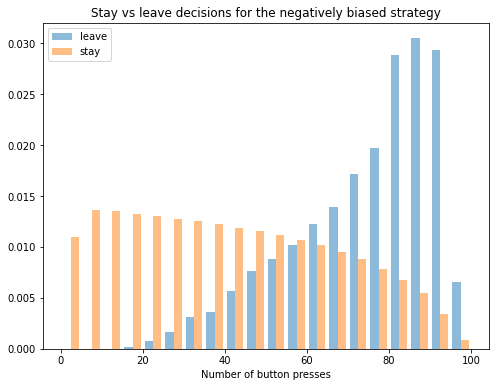

In [13]:
negative_bias_data = get_wins_fails(negative_bias.get_decisions(wins_more_fails=True))

plt.figure(figsize=(8,6))
plt.hist(negative_bias_data, alpha=0.5, label=['leave', 'stay'], range=[0.0, 100.0], bins=20, density=True)
plt.legend(loc="upper left")
plt.title("Stay vs leave decisions for the negatively biased strategy")
plt.xlabel("Number of button presses")
plt.savefig('Plots/stay_vs_leave_negative_bias.png',dpi=120)
plt.show()

In [14]:
cost = 0.4
button = Button('Bernoulli', prior=(1, 1))
policy = Policy('Bernoulli', prior=(1, 1), cost=cost)
unbiased_cost_record = record_full_trials(100, 10000, button, policy, cost=cost)
unbiased_cost = Decision_Process(unbiased_cost_record)

Total number of stay decisions is 644051
Total number of leave decisions is 13292


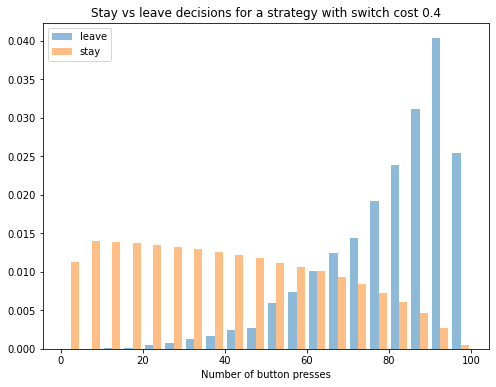

In [15]:
unbiased_cost_data = get_wins_fails(unbiased_cost.get_decisions(wins_more_fails=True))

plt.figure(figsize=(8,6))
plt.hist(unbiased_cost_data, alpha=0.5, label=['leave', 'stay'], range=[0.0, 100.0], bins=20, density=True)
plt.legend(loc="upper left")
plt.title("Stay vs leave decisions for a strategy with switch cost " + str(cost))
plt.xlabel("Number of button presses")
plt.savefig('Plots/stay_vs_leave_cost.png',dpi=120)
plt.show()

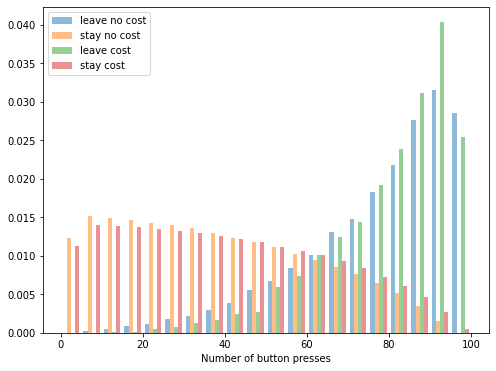

In [16]:
plt.figure(figsize=(8,6))
plt.hist(unbiased_data + unbiased_cost_data, alpha=0.5,
         label=['leave no cost', 'stay no cost', 'leave cost', 'stay cost'],
         range=[0.0, 100.0], bins=20, density=True)
plt.legend(loc="upper left")
plt.xlabel("Number of button presses")
plt.savefig('Plots/stay_vs_leave_unbias_vs_cost.png',dpi=120)
plt.show()

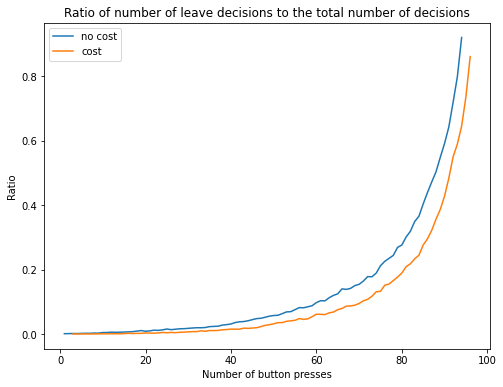

In [17]:
unbiased_aggr = aggregate_wins_fails(unbiased.get_decisions(wins_more_fails=False))
unbiased_cost_aggr = aggregate_wins_fails(unbiased_cost.get_decisions(wins_more_fails=False))

plt.figure(figsize=(8,6))
plt.title('Ratio of number of leave decisions to the total number of decisions')
plt.xlabel("Number of button presses")
plt.ylabel("Ratio")
plt.plot(unbiased_aggr[:,0],unbiased_aggr[:,1]/(unbiased_aggr[:,1]+unbiased_aggr[:,2]), label='no cost')
plt.plot(unbiased_cost_aggr[:,0],unbiased_cost_aggr[:,1]/(unbiased_cost_aggr[:,1]+unbiased_cost_aggr[:,2]), label='cost')
plt.legend(loc="upper left")
plt.savefig('Plots/ratio_unbiased_cost.png',dpi=120)
plt.show()

# Experiment part

In [18]:
df = pd.read_pickle('pilot_3_results.pkl')
experiment = Decision_Process(df)

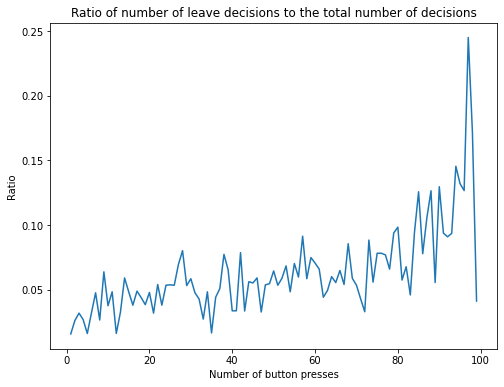

In [19]:
experiment_aggr = aggregate_wins_fails(experiment.get_decisions(wins_more_fails=False))

plt.figure(figsize=(8,6))
plt.title("Ratio of number of leave decisions to the total number of decisions")
plt.xlabel("Number of button presses")
plt.ylabel("Ratio")
plt.plot(experiment_aggr[:,0],experiment_aggr[:,1]/(experiment_aggr[:,1]+experiment_aggr[:,2]))
plt.savefig('Plots/ratio_experiment.png',dpi=120)
plt.show()

In [20]:
num_buttons, top_button_to_all = experiment.analyze_largest_contribution()

The average number of buttons explored is 6.63
The average reward received is 64.97
Out of 200 subjects in total 138 subjects (or 69.00%) got the largest contribution from the last button
The average contribution of the button with the largest contribution is 71.11 %


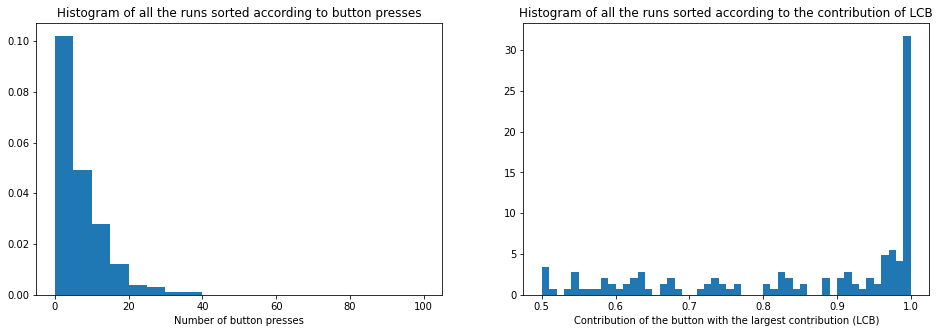

In [21]:
fig = plt.figure(figsize=(16,5))
ax = fig.add_subplot(121)
ax.set_title("Histogram of all the runs sorted according to button presses")
ax.set_xlabel("Number of button presses")
ax.hist(num_buttons, density=True, bins=20, range=(0, 100));

ax = fig.add_subplot(122)
ax.set_title("Histogram of all the runs sorted according to the contribution of LCB")
ax.set_xlabel("Contribution of the button with the largest contribution (LCB)")
ax.hist(top_button_to_all, density=True, bins=50, range=(0.5,1));

plt.show()

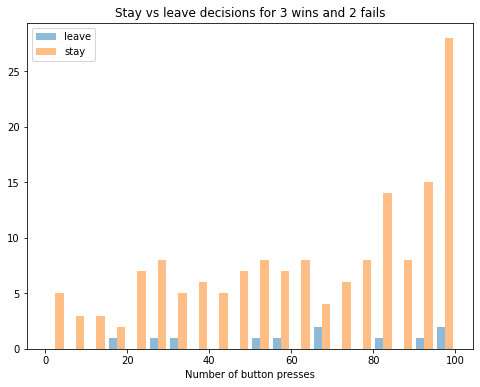

In [22]:
plot_fixed_win_fail_distribution(experiment.get_decisions(), 3, 2)